
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-1/Laboratorios/Laboratorio_13_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.


---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

## Caso 1: Redes Tipo Ising

Se genera una red con 1 y -1 en posiciones aleatorias de tamañano $n \times m$. Similar al modelo de Ising con una red de espínes en posiciones de la red.

In [2]:
# función para generar patrones balanceados
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

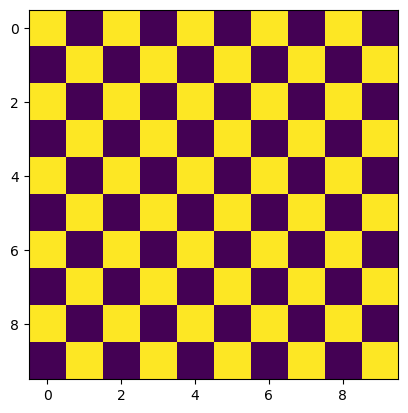

In [3]:
# definimos el tamaño de nuestra red 
m, n = 10, 10 
N = m*n
h, v, d = patrones_balanceados(m, n)
plt.imshow(d)

In [4]:
# calculo paso por paso de la energía de la red

# definimos el estado de la red como un vector columna 
estado = np.concat(d).reshape(N, 1)
psi = np.concat(d).reshape(1, N)

# matriz de pesos w_ij de acuerdo a la regla de Hebb
def pesos_ij(psi, N):
    w = np.zeros((N, N))
    for i in range(0, N):
        for j in range(0, N):
            if(i!= j):
                w[i,j] = psi[0][i]*psi[0][j]
    return w

w_ij = pesos_ij(psi, N)


# calcular el campo local h_i
hi = w_ij @ np.transpose(psi[0])

# calcular la energía de la red
energia = -0.5 * estado.T @ w_ij @ estado
energia

array([[-4950.]])

In [5]:
# cálculo en terminos de funciones

# funcion para calcular el campo local
def campo_local(w_ij, estado):
    campo = w_ij @ estado
    return campo

# funcion para calcular la energia total de la red (forma matricial)
def energiaTotal(estado, H):
    return  -0.5 *estado.T @ H

# calcular campo y energia total de la red 
h = campo_local(w_ij, estado)
eT =energiaTotal(estado, h)
print(eT)

[[-4950.]]


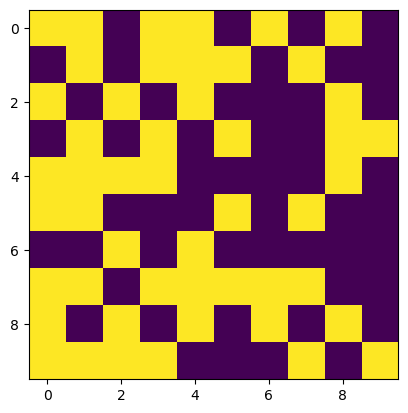

In [6]:
# agregamos ruido a la imagen 
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (m, n)))

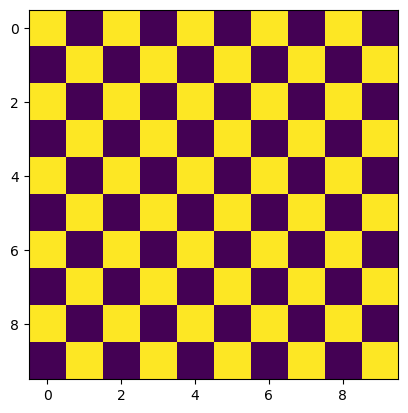

In [7]:
# ciclo de actualización de la red Hopfield
'''Para cada iteración, seleccionamos un índice aleatorio de la red y calculamos el campo local correspondiente. 
Luego, actualizamos el estado del nodo en ese índice según la dirección del campo local. Esto garantiza que la red
evolucione hacia un estado de menor energía, acercándose a uno de los patrones almacenados.'''  

for i in range(500):
    index = np.random.randint(0, N)
    h = campo_local(w_ij, s_ruido)
    direccion = np.sign(h[index])
    if direccion > 0:
        s_ruido[index] = 1
    else:
        s_ruido[index] = -1

plt.imshow(np.reshape(s_ruido, (m, n)))

## Caso 2:Aplicación a una Imagen real

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


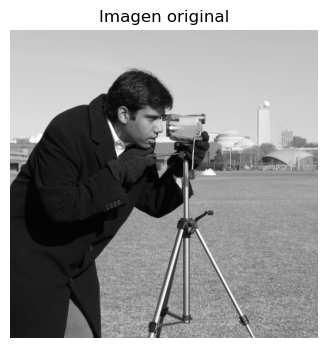

In [8]:
img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

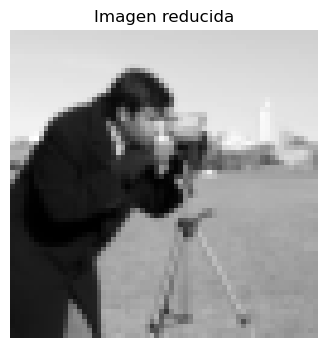

In [9]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

In [10]:
# dimensiones de la imagen reducida
n_img = img_small.shape[0]
m_img = img_small.shape[1]

N_img = n_img * m_img

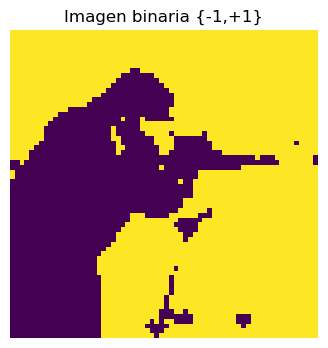

In [11]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin)
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [12]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido2(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido_img = agregar_ruido2(np.concat(img_bin), frac=frac_ruido, seed=123)
s_ruido_img_orig = s_ruido_img.copy()

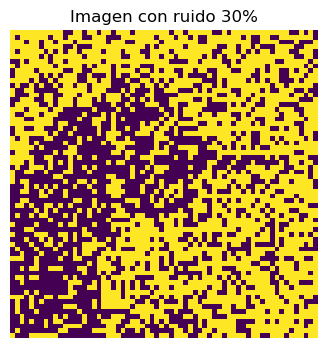

In [13]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido_img.reshape(n, m))
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

In [ ]:
# definimos el estado de la red (la imagen binaria) como un vector
psi_img = np.concat(img_bin).reshape(1, N_img)

#calcuamos los pesos de la red Hopfield para la imagen binaria 
wij_img = pesos_ij(psi_img, N_img)

In [15]:
def ef(wij, s):
    return -0.5 * s @ wij @ s

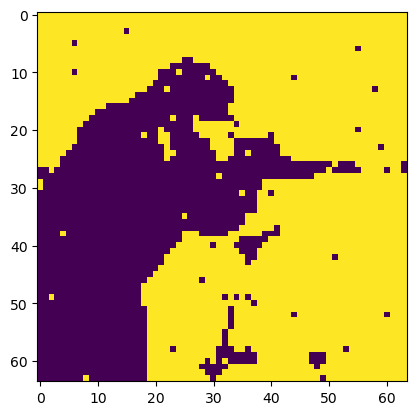

In [16]:
# proceso de iteración para la imagen con ruido
energias_after = []

for i in range(15000):
    index = np.random.randint(0, N_img)
    h = campo_local(wij_img, s_ruido_img)
    direccion = np.sign(h[index])
    if direccion > 0:
        s_ruido_img[index] = 1
    else:
        s_ruido_img[index] = -1

    E = ef(wij_img, s_ruido_img)
    energias_after.append(E)

plt.imshow(np.reshape(s_ruido_img, (m_img, n_img)))

Text(0.5, 1.0, 'Imagen Recuperada')

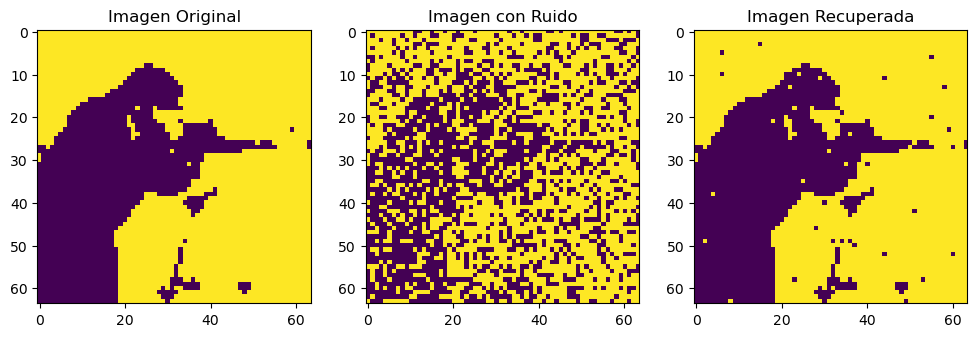

In [17]:
# mostrar la imagen original y la imagen recuperada por la red Hopfield
plt.figure(figsize=(12,4))
plt.subplot(1, 3, 1)
plt.imshow(np.reshape(psi_img, (m_img, n_img)))
plt.title('Imagen Original')
plt.subplot(1, 3, 2)
plt.imshow(np.reshape(s_ruido_img_orig, (m_img, n_img)))
plt.title('Imagen con Ruido')
plt.subplot(1, 3, 3)
plt.imshow(np.reshape(s_ruido_img, (m_img, n_img)))
plt.title('Imagen Recuperada')

## Preguntas guía 

1. ¿La energía disminuye durante la recuperación?


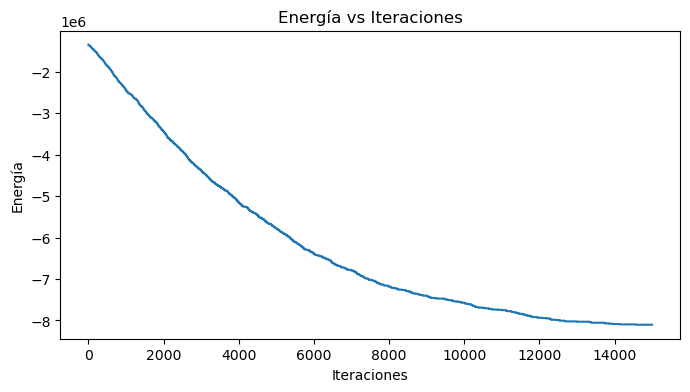

In [18]:
energias_afer = np.array(energias_after)
iter = np.arange(len(energias_afer))
plt.figure(figsize=(8,4))
plt.title('Energía vs Iteraciones')
plt.plot(iter, energias_afer)
plt.xlabel('Iteraciones')
plt.ylabel('Energía')
plt.show()

Se aprecía que la energía efectivamente disminuye durante la recuperación. Dado que estámos haciendo una recuperación asincrónica (un píxel a la vez y con peosos simétricos), la energía nunca aumenta. En cada actualización de $s_i' = sign(h_i)$ la energía puede disminuir o en algunos pasos permanecer igual.  Al aumentar el número de iteraciones la red converge a un mínimo de energía.

2. ¿La red recupera exactamente la imagen original?

En este caso donde se tiene una sola imagen y un ruido del $30%$ , se recupera exactamente la imagen original. Nuesta imagen almacenada es un atractor en el paísaje de energía que, en este caso, hace que la imagen con ruído converja hasta su mínimo de energía. 

3. ¿Qué ocurre si aumenta el nivel de ruido?

Al aumentar el ruido, la diferencia entre el estado inicial y el patrón almacenado es mayor. Puede existir una probabilidad de que quede por fuera de la zona de atracción del patrón de energía y no converja al mínimo. 

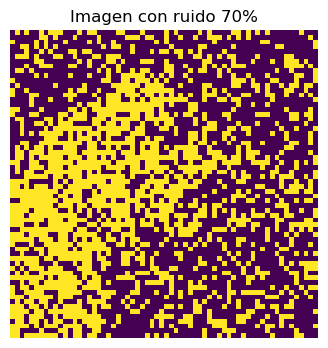

In [62]:
s_ruido_img_70 = agregar_ruido2(np.concat(img_bin), frac=0.7, seed=123)
plt.figure(figsize=(4,4))
plt.imshow(s_ruido_img_70.reshape(n, m))
plt.title(f"Imagen con ruido {0.70*100:.0f}%")
plt.axis("off")
plt.show()


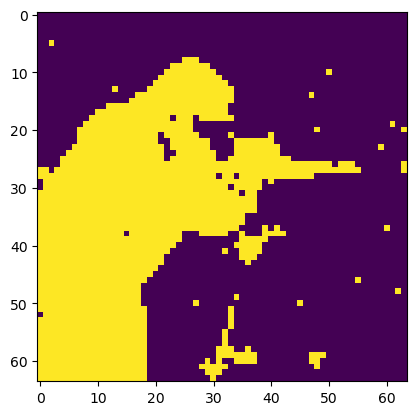

In [ ]:
# proceso de iteración para la imagen con mayor ruido

for i in range(15000):
    index = np.random.randint(0, N_img)
    h = campo_local(w_ij, s_ruido_img_70)
    direccion = np.sign(h[index])
    if direccion > 0:
        s_ruido_img_70[index] = 1
    else:
        s_ruido_img_70[index] = -1

plt.imshow(np.reshape(s_ruido_img_70, (m_img, n_img)))

Se observa un patrón inverso , el alto grado de desorden introduce un patrón inverso.

4. ¿Qué pasa si se almacenan varias imágenes?

Vamos a analizar el caso donde se almacenan 4 imágenes

In [96]:
# cargamos 3 imagenes en blanco y negro
img1 = data.camera()   # imagen 512x512 en escala de grises
img2 =rgb2gray(data.cat())  # imagen 512x512 convertida a escala de grises 
img3 =rgb2gray(data.coffee()) 
img4 = data.horse()
#plt.figure(figsize=(12,4))
#plt.subplot(1, 3, 1)
#plt.imshow(img1, cmap="gray")
#plt.subplot(1, 3, 2)
#plt.imshow(img2, cmap="gray")
#plt.subplot(1,3,3)
#plt.imshow(img3, cmap="gray")
#plt.axis("off")
#plt.show()

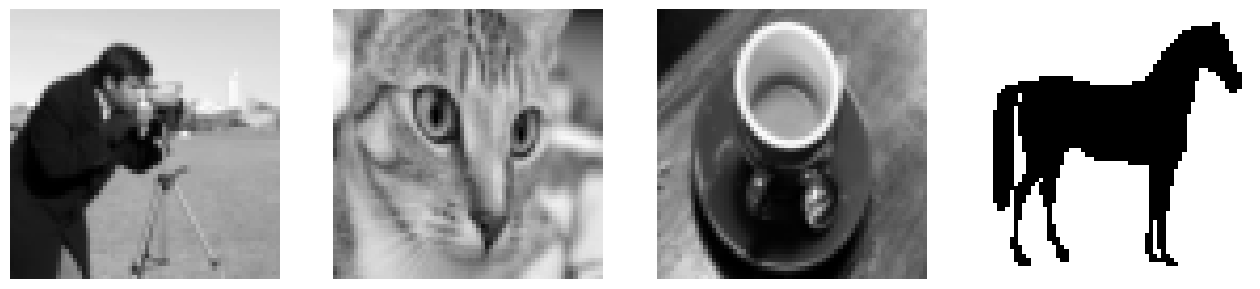

In [100]:
# ============================================================
# Reducir imagenes, todas al mismo tamaño 
# ============================================================

n = 64
m = 64
Nimg = m*n

img1_small = resize(img1, (n, m), anti_aliasing=True)
img2_small = resize(img2, (n, m), anti_aliasing=True)
img3_small = resize(img3, (n, m), anti_aliasing=True)
img4_small = resize(img4, (n, m), anti_aliasing=False)


plt.figure(figsize=(16,4))
plt.subplot(1, 4, 1)
plt.axis("off")
plt.imshow(img1_small, cmap="gray")
plt.subplot(1, 4, 2)
plt.axis("off")
plt.imshow(img2_small, cmap="gray")
plt.subplot(1,4,3)
plt.imshow(img3_small, cmap="gray")
plt.axis("off")
plt.subplot(1,4,4)
plt.imshow(img4_small, cmap="gray")
plt.axis("off")
plt.show()

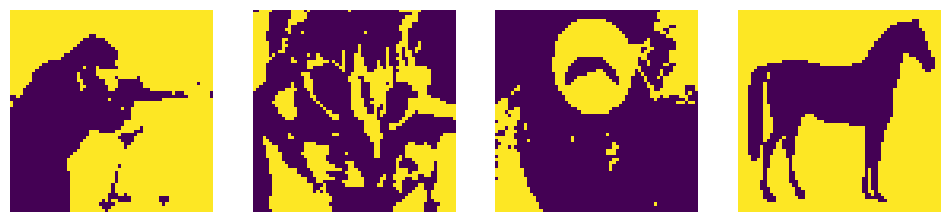

In [102]:
# imagenes binarias 
img_bin1 = np.where(img1_small > threshold, 1, -1)
img_bin2 = np.where(img2_small > threshold, 1, -1)
img_bin3 = np.where(img3_small > threshold, 1, -1)
img_bin4 = np.where(img4_small > threshold, 1, -1)


plt.figure(figsize=(12,4))
plt.subplot(1, 4, 1)
plt.imshow(img_bin1)
plt.axis("off")
plt.subplot(1, 4, 2)
plt.imshow(img_bin2)
plt.axis("off")
plt.subplot(1, 4, 3)
plt.imshow(img_bin3)
plt.axis("off")
plt.subplot(1, 4, 4)
plt.imshow(img_bin4)
plt.axis("off")
plt.show()

Y vamos a introducirle ruido a la imagen 2, para intentar recuperarla después

In [103]:
s_ruido_img2 = agregar_ruido2(np.concat(img_bin2), frac=0.3, seed=123)
s_ruido_img2_orig = s_ruido_img2.copy()
#plt.imshow(s_ruido_img2.reshape(n, m))

In [ ]:
# definimos el estado que contiene las 4 imagenes (vector fila)
psi = np.concat([img_bin1, img_bin2, img_bin3]).reshape(3, Nimg)


# calculamos los pesos según la regla de Hebb. Los pesos contienen info de las 4 imagenes 
def pesos_ij(psi, N):
    w = (psi.T @ psi) / N
    np.fill_diagonal(w, 0)
    return w


w_ij = pesos_ij(psi, N)

In [107]:
# proceso de iteración para la imagen con mayor ruido

for i in range(15000):
    index = np.random.randint(0, N_img)
    h = campo_local(w_ij, s_ruido_img2)
    direccion = np.sign(h[index])
    if direccion > 0:
        s_ruido_img2[index] = 1
    else:
        s_ruido_img2[index] = -1

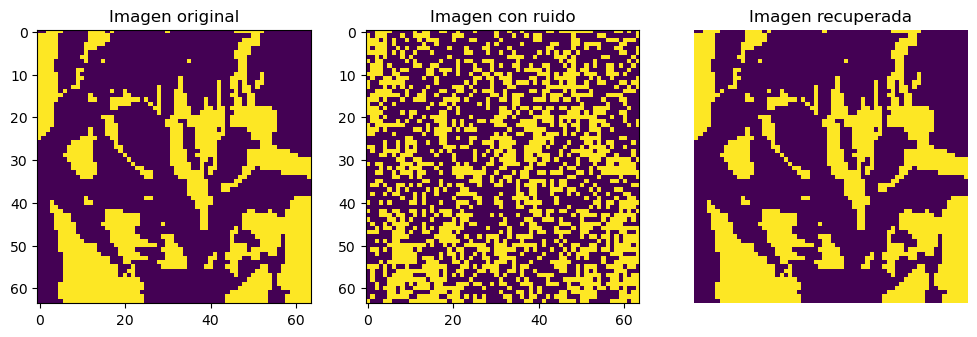

In [108]:
plt.figure(figsize=(12,4))
plt.subplot(1, 3, 1)
plt.imshow(np.reshape(img_bin2, (m, n)))
plt.title('Imagen original')
plt.subplot(1, 3, 2)
plt.title('Imagen con ruido')
plt.imshow(np.reshape(s_ruido_img2_orig, (m, n)))
plt.subplot(1, 3, 3)
plt.title('Imagen recuperada')
plt.imshow(np.reshape(s_ruido_img2, (m, n)))
plt.axis("off")
plt.show()

5. ¿Aparecen estados espurios?

En este caso  en particular, no aparecen estados espurios evidentes. Sin embargo, si se aumenta el número de patrones es muy probable que aparezcan, ya que los mínimos de energía pueden no corresponden a patrones almacenados.

Los estados espurios pueden surgir por ejemplocomo mezclas de los patrones o patrones inversos. Esto se debe a que al almacenar varias patrones aparece interferencia entre ellos. La regla de Hebb suma las contribuciones de todos, y pueden causar ruido entre sí.  

6. ¿La recuperación depende del orden en que se actualizan los píxeles?

Sí. La actualización asincrónica solo nos garantiza que la energía disminuye independientemente del orden en que se actualicen los píxeles. Sin embargo, al tener varios patrones y ruido considerable tenemos un paísaje de energía más complejo. El orden de actualización puede llevar a distintos atractores finales (mínimos de energía), por lo que la recuperación de la energía si puede llegar a depender del orden. 

7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

La actualización asrincrónica es la que usamos aquí. Cada píxel se actualiza a la vez (sea de forma aleatoria o sencuencial) mientras que los demás permanecen en el mismo estado. Se garantiza que la energia de la red no aumenta y evoluciona hacía uno de sus mínimos.


Por otro lado, la actualización sincrónica actualiza todos los píxeles a la vez. Todos utilizan su estado anterior para calcular la nueva configuración al mismo tiempo. Aquí no se garantiza el decenso de energía monótono, creando ciclos donde se oscila entre 2 estados de energía. Es computacionalmente más eficiente, pero es inestable. Puede funcionar mejor para sistemas con poco ruido.
